In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped:", e)


Mounted at /content/drive


## 2. Existing checkpoint paths

In [ ]:

BASE_DIR = Path("/content/drive/MyDrive/Linguistics_feature")

AI_STRUCTURAL_PATH = BASE_DIR / "raid_chatgpt_structural_checkpoint.csv"
AI_PPL_PATH = BASE_DIR / "raid_chatgpt_perplexity_checkpoint.csv"

HUMAN_STRUCTURAL_PATH = BASE_DIR / "raid_human_structural_checkpoint.csv"
HUMAN_PPL_PATH = BASE_DIR / "raid_human_perplexity_checkpoint.csv"

AI_FEATURE_PATH = BASE_DIR / "raid_chatgpt_linguistic_features_v2.csv"
HUMAN_FEATURE_PATH = BASE_DIR / "raid_human_linguistic_features.csv"

OUTPUT_DIR = BASE_DIR / "final_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_COLS = [
    "word_count",
    "lexical_diversity",
    "avg_sentence_length",
    "sentence_length_std",
    "burstiness",
    "punctuation_density",
    "readability_flesch",
    "perplexity",
]

CONVERGENCE_TOLERANCE = 0.05

for name, path in {
    "AI structural": AI_STRUCTURAL_PATH,
    "AI perplexity": AI_PPL_PATH,
    "Human structural": HUMAN_STRUCTURAL_PATH,
    "Human perplexity": HUMAN_PPL_PATH,
}.items():
    print(f"{name:18s}: {'FOUND' if path.exists() else 'MISSING'} | {path}")


AI structural     : FOUND | /content/drive/MyDrive/Linguistics_feature/raid_chatgpt_structural_checkpoint.csv
AI perplexity     : FOUND | /content/drive/MyDrive/Linguistics_feature/raid_chatgpt_perplexity_checkpoint.csv
Human structural  : FOUND | /content/drive/MyDrive/Linguistics_feature/raid_human_structural_checkpoint.csv
Human perplexity  : FOUND | /content/drive/MyDrive/Linguistics_feature/raid_human_perplexity_checkpoint.csv


In [ ]:
def merge_checkpoint_files(structural_path, ppl_path, output_path, dataset_name):
    structural = pd.read_csv(structural_path)
    ppl = pd.read_csv(ppl_path)

    print("\n" + "=" * 80)
    print(dataset_name)
    print("=" * 80)
    print("Structural:", structural.shape)
    print("Perplexity checkpoint:", ppl.shape)

    required = {"_feature_row_id", "perplexity"}
    if not required.issubset(ppl.columns):
        raise ValueError(
            f"{dataset_name}: perplexity checkpoint must contain "
            f"{sorted(required)}. Found {ppl.columns.tolist()}"
        )

    ppl = (
        ppl[["_feature_row_id", "perplexity"]]
        .drop_duplicates("_feature_row_id", keep="last")
        .copy()
    )
    ppl["_feature_row_id"] = pd.to_numeric(
        ppl["_feature_row_id"], errors="coerce"
    )
    ppl["perplexity"] = pd.to_numeric(
        ppl["perplexity"], errors="coerce"
    )
    ppl = ppl.dropna(subset=["_feature_row_id"])
    ppl["_feature_row_id"] = ppl["_feature_row_id"].astype(int)

    structural = structural.reset_index(drop=True).copy()
    structural["_feature_row_id"] = np.arange(len(structural), dtype=int)

    if "perplexity" in structural.columns:
        structural = structural.drop(columns=["perplexity"])

    final_df = structural.merge(
        ppl,
        on="_feature_row_id",
        how="left",
        validate="one_to_one",
    )

    missing_ppl = int(final_df["perplexity"].isna().sum())
    print("Merged rows:", len(final_df))
    print("Rows with perplexity:", int(final_df["perplexity"].notna().sum()))
    print("Rows missing perplexity:", missing_ppl)

    if missing_ppl:
        completion = 100 * final_df["perplexity"].notna().mean()
        raise RuntimeError(
            f"{dataset_name}: perplexity checkpoint is only "
            f"{completion:.2f}% complete. {missing_ppl:,} rows are missing. "
            "Resume the existing perplexity checkpoint before final analysis."
        )

    missing_features = [f for f in FEATURE_COLS if f not in final_df.columns]
    if missing_features:
        raise ValueError(
            f"{dataset_name}: missing linguistic features: {missing_features}"
        )

    for feature in FEATURE_COLS:
        final_df[feature] = pd.to_numeric(final_df[feature], errors="coerce")

    final_df[FEATURE_COLS] = final_df[FEATURE_COLS].replace(
        [np.inf, -np.inf], np.nan
    )

    print("\nMissing feature values:")
    display(final_df[FEATURE_COLS].isna().sum().rename("missing").to_frame())

    final_df = (
        final_df.sort_values("_feature_row_id")
        .drop(columns=["_feature_row_id"])
        .reset_index(drop=True)
    )

    final_df.to_csv(output_path, index=False)
    print("\nSAVED:", output_path)
    print("Final shape:", final_df.shape)

    return final_df


ai_df = merge_checkpoint_files(
    AI_STRUCTURAL_PATH,
    AI_PPL_PATH,
    AI_FEATURE_PATH,
    "ChatGPT + adversarial data",
)

human_df = merge_checkpoint_files(
    HUMAN_STRUCTURAL_PATH,
    HUMAN_PPL_PATH,
    HUMAN_FEATURE_PATH,
    "Matched human data",
)

print("\nBoth final linguistic-feature files created successfully.")
print(AI_FEATURE_PATH)
print(HUMAN_FEATURE_PATH)



ChatGPT + adversarial data
Structural: (320904, 18)
Perplexity checkpoint: (320904, 2)
Merged rows: 320904
Rows with perplexity: 320904
Rows missing perplexity: 0

Missing feature values:


,missing
word_count,0
lexical_diversity,1
avg_sentence_length,1
sentence_length_std,1
burstiness,1
punctuation_density,0
readability_flesch,1
perplexity,0



SAVED: /content/drive/MyDrive/Linguistics_feature/raid_chatgpt_linguistic_features_v2.csv
Final shape: (320904, 19)

Matched human data
Structural: (13371, 14)
Perplexity checkpoint: (13371, 2)
Merged rows: 13371
Rows with perplexity: 13371
Rows missing perplexity: 0

Missing feature values:


,missing
word_count,0
lexical_diversity,1
avg_sentence_length,1
sentence_length_std,1
burstiness,1
punctuation_density,0
readability_flesch,1
perplexity,0



SAVED: /content/drive/MyDrive/Linguistics_feature/raid_human_linguistic_features.csv
Final shape: (13371, 15)

Both final linguistic-feature files created successfully.
/content/drive/MyDrive/Linguistics_feature/raid_chatgpt_linguistic_features_v2.csv
/content/drive/MyDrive/Linguistics_feature/raid_human_linguistic_features.csv


In [ ]:
print("AI shape:", ai_df.shape)
print("Human shape:", human_df.shape)

print("\nAI columns:")
print(ai_df.columns.tolist())

print("\nHuman columns:")
print(human_df.columns.tolist())

ai_sources = set(ai_df["source_id"].dropna().astype(str))
human_sources = set(human_df["source_id"].dropna().astype(str))

print("\nUnique AI source_id:", len(ai_sources))
print("Unique Human source_id:", len(human_sources))
print("Matched source_id:", len(ai_sources & human_sources))

if ai_sources:
    print(
        "Human source coverage:",
        f"{100 * len(ai_sources & human_sources) / len(ai_sources):.2f}%"
    )


AI shape: (320904, 19)
Human shape: (13371, 15)

AI columns:
['id', 'adv_source_id', 'source_id', 'model', 'decoding', 'repetition_penalty', 'attack', 'domain', 'title', 'prompt', 'generation', 'word_count', 'lexical_diversity', 'avg_sentence_length', 'sentence_length_std', 'burstiness', 'punctuation_density', 'readability_flesch', 'perplexity']

Human columns:
['id', 'source_id', 'domain', 'title', 'text', 'model', 'attack', 'word_count', 'lexical_diversity', 'avg_sentence_length', 'sentence_length_std', 'burstiness', 'punctuation_density', 'readability_flesch', 'perplexity']

Unique AI source_id: 13371
Unique Human source_id: 13371
Matched source_id: 13371
Human source coverage: 100.00%


In [ ]:

required_ai = [
    "id", "adv_source_id", "source_id", "attack", "domain"
] + FEATURE_COLS

required_human = ["source_id", "domain"] + FEATURE_COLS

missing_ai = [c for c in required_ai if c not in ai_df.columns]
missing_human = [c for c in required_human if c not in human_df.columns]

if missing_ai:
    raise KeyError(f"AI file missing columns: {missing_ai}")
if missing_human:
    raise KeyError(f"Human file missing columns: {missing_human}")

for col in ["id", "adv_source_id", "source_id"]:
    ai_df[col] = ai_df[col].astype("string")

if "id" in human_df.columns:
    human_df["id"] = human_df["id"].astype("string")
human_df["source_id"] = human_df["source_id"].astype("string")

ai_df["attack"] = ai_df["attack"].astype("string").str.strip()
ai_df["domain"] = ai_df["domain"].astype("string").str.strip()
human_df["domain"] = human_df["domain"].astype("string").str.strip()

for feature in FEATURE_COLS:
    ai_df[feature] = pd.to_numeric(ai_df[feature], errors="coerce")
    human_df[feature] = pd.to_numeric(human_df[feature], errors="coerce")

attack_norm = (
    ai_df["attack"]
    .fillna("")
    .str.lower()
    .str.strip()
)

original_ai = ai_df[attack_norm.eq("none")].copy()
attacked_ai = ai_df[~attack_norm.eq("none")].copy()

print("Original AI rows:", len(original_ai))
print("Attacked AI rows:", len(attacked_ai))
display(
    attacked_ai["attack"]
    .value_counts(dropna=False)
    .rename_axis("attack")
    .reset_index(name="rows")
)


Original AI rows: 26742
Attacked AI rows: 294162


,attack,rows
0,whitespace,26742
1,upper_lower,26742
2,synonym,26742
3,paraphrase,26742
4,number,26742
5,insert_paragraphs,26742
6,perplexity_misspelling,26742
7,homoglyph,26742
8,article_deletion,26742
9,alternative_spelling,26742


In [ ]:

original_id_set = set(original_ai["id"].dropna().astype(str))
adv_ids = attacked_ai["adv_source_id"].dropna().astype(str)
linked = adv_ids.isin(original_id_set)

print("Original unique IDs:", original_ai["id"].nunique())
print("Attacked rows:", len(attacked_ai))
print("Attacked rows with adv_source_id:", len(adv_ids))
print("Linked adv_source_id → original id:", int(linked.sum()))

if len(adv_ids):
    print("Pairing coverage:", f"{linked.mean() * 100:.2f}%")

original_unique = original_ai.drop_duplicates("id").copy()

orig = original_unique[
    ["id", "source_id", "domain"] + FEATURE_COLS
].rename(
    columns={
        "id": "original_id",
        "source_id": "source_id_original",
        "domain": "domain_original",
        **{f: f"{f}_original" for f in FEATURE_COLS},
    }
)

att_cols = [
    "id", "adv_source_id", "source_id", "attack", "domain"
] + FEATURE_COLS

for optional in ["model", "decoding", "repetition_penalty"]:
    if optional in attacked_ai.columns:
        att_cols.append(optional)

att = attacked_ai[att_cols].rename(
    columns={
        "id": "attacked_id",
        "source_id": "source_id_attacked",
        "domain": "domain_attacked",
        **{f: f"{f}_attacked" for f in FEATURE_COLS},
    }
)

pairs = att.merge(
    orig,
    left_on="adv_source_id",
    right_on="original_id",
    how="inner",
    validate="many_to_one",
)

pairs["source_id"] = pairs["source_id_original"]
pairs["domain"] = pairs["domain_original"]

print("\nPaired attacked rows:", len(pairs))
print(
    "Paired percentage:",
    f"{100 * len(pairs) / len(attacked_ai):.2f}%"
    if len(attacked_ai) else "N/A"
)

source_agreement = (
    pairs["source_id_attacked"].astype(str)
    == pairs["source_id_original"].astype(str)
)
domain_agreement = (
    pairs["domain_attacked"].astype(str)
    == pairs["domain_original"].astype(str)
)

print("source_id agreement:", f"{source_agreement.mean()*100:.2f}%")
print("domain agreement:", f"{domain_agreement.mean()*100:.2f}%")

display(
    pairs[
        ["attacked_id", "adv_source_id", "original_id",
         "source_id", "attack", "domain"]
    ].head()
)


Original unique IDs: 26742
Attacked rows: 294162
Attacked rows with adv_source_id: 294162
Linked adv_source_id → original id: 294162
Pairing coverage: 100.00%

Paired attacked rows: 294162
Paired percentage: 100.00%
source_id agreement: 100.00%
domain agreement: 100.00%


,attacked_id,adv_source_id,original_id,source_id,attack,domain
0,dd214482-e8ad-432a-9f5a-8ac20a9ce7ad,966c7ba3-c272-431e-a058-73d9d8480e17,966c7ba3-c272-431e-a058-73d9d8480e17,e5e058ce-be2b-459d-af36-32532aaba5ff,whitespace,abstracts
1,e7d6a80f-88ee-4ee3-a982-1347b947fbcb,bd8ef628-ada7-4f49-84b2-456f65a22839,bd8ef628-ada7-4f49-84b2-456f65a22839,e5e058ce-be2b-459d-af36-32532aaba5ff,whitespace,abstracts
2,2f4bfd7c-c332-48e1-81d3-26509dc7ec3f,b8ba7698-aca6-4333-b10d-6cd48d5f575b,b8ba7698-aca6-4333-b10d-6cd48d5f575b,f95b107b-d176-4af5-90f7-4d0bb20caf93,whitespace,abstracts
3,fe3dc52d-ee8c-4907-9fcd-076f4ee0cef3,4936ee69-adab-4225-a39f-170bde100cab,4936ee69-adab-4225-a39f-170bde100cab,f95b107b-d176-4af5-90f7-4d0bb20caf93,whitespace,abstracts
4,9b1c5e53-fe56-458a-932e-38a01a4fe877,9b233912-6936-47ed-b3c4-52f858fbb7f6,9b233912-6936-47ed-b3c4-52f858fbb7f6,856d8972-9e3d-4544-babc-0fe16f21e04d,whitespace,abstracts


In [ ]:

variant_counts = (
    pairs.groupby(
        ["attack", "domain", "original_id"],
        dropna=False
    )
    .size()
    .rename("attack_variants")
    .reset_index()
)

print(
    "Original/attack groups with >1 attacked variant:",
    int((variant_counts["attack_variants"] > 1).sum())
)
print(
    "Maximum variants for one original under one attack:",
    int(variant_counts["attack_variants"].max())
    if len(variant_counts) else 0
)

display(
    variant_counts[
        variant_counts["attack_variants"] > 1
    ]
    .sort_values("attack_variants", ascending=False)
    .head(20)
)


Original/attack groups with >1 attacked variant: 0
Maximum variants for one original under one attack: 1


,attack,domain,original_id,attack_variants


In [ ]:

def numeric_array(values):
    return (
        pd.to_numeric(pd.Series(values), errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .astype(float)
        .to_numpy()
    )


def cohen_dz(before, after):
    before = np.asarray(before, dtype=float)
    after = np.asarray(after, dtype=float)
    valid = np.isfinite(before) & np.isfinite(after)
    before, after = before[valid], after[valid]

    if len(before) < 2:
        return np.nan

    diff = after - before
    sd = np.std(diff, ddof=1)

    if not np.isfinite(sd) or np.isclose(sd, 0):
        return 0.0 if np.isclose(np.mean(diff), 0) else np.nan

    return float(np.mean(diff) / sd)


def hedges_g(x, y):
    x = numeric_array(x)
    y = numeric_array(y)

    n1, n2 = len(x), len(y)
    if n1 < 2 or n2 < 2:
        return np.nan

    v1 = np.var(x, ddof=1)
    v2 = np.var(y, ddof=1)
    df = n1 + n2 - 2

    pooled = (((n1 - 1) * v1) + ((n2 - 1) * v2)) / df

    if not np.isfinite(pooled) or pooled <= 0:
        return 0.0 if np.isclose(np.mean(x), np.mean(y)) else np.nan

    d = (np.mean(x) - np.mean(y)) / np.sqrt(pooled)
    correction = 1 - 3 / (4 * df - 1) if (4 * df - 1) > 0 else 1

    return float(correction * d)


def paired_tests(before, after):
    before = np.asarray(before, dtype=float)
    after = np.asarray(after, dtype=float)
    valid = np.isfinite(before) & np.isfinite(after)
    before, after = before[valid], after[valid]

    if len(before) < 2:
        return np.nan, np.nan

    try:
        p_t = float(stats.ttest_rel(before, after).pvalue)
    except Exception:
        p_t = np.nan

    try:
        diff = after - before
        p_w = 1.0 if np.allclose(diff, 0) else float(
            stats.wilcoxon(before, after, zero_method="wilcox").pvalue
        )
    except Exception:
        p_w = np.nan

    return p_t, p_w


def mean_change_ci(before, after, confidence=0.95):
    before = np.asarray(before, dtype=float)
    after = np.asarray(after, dtype=float)
    valid = np.isfinite(before) & np.isfinite(after)
    diff = after[valid] - before[valid]

    if len(diff) < 2:
        return np.nan, np.nan

    mean_diff = np.mean(diff)
    se = stats.sem(diff)

    if not np.isfinite(se):
        return np.nan, np.nan

    critical = stats.t.ppf((1 + confidence) / 2, len(diff) - 1)
    return (
        float(mean_diff - critical * se),
        float(mean_diff + critical * se),
    )


def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    output = np.full(len(p), np.nan)
    valid = np.isfinite(p)

    if valid.sum() == 0:
        return output

    pv = p[valid]
    order = np.argsort(pv)
    ranked = pv[order]
    m = len(ranked)

    adjusted = ranked * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    temp = np.empty(m)
    temp[order] = adjusted
    output[np.where(valid)[0]] = temp

    return output


def percent_change(before_mean, after_mean):
    if not np.isfinite(before_mean) or np.isclose(before_mean, 0):
        return np.nan
    return float(100 * (after_mean - before_mean) / abs(before_mean))


def movement_label(value):
    if not np.isfinite(value):
        return "Insufficient data"
    if value > CONVERGENCE_TOLERANCE:
        return "Toward Human"
    if value < -CONVERGENCE_TOLERANCE:
        return "Away from Human"
    return "Little/No Change"


In [ ]:

def aggregate_attack_pairs(subset, feature):
    orig_col = f"{feature}_original"
    att_col = f"{feature}_attacked"

    temp = subset[
        ["original_id", "source_id", orig_col, att_col]
    ].copy()

    temp[orig_col] = pd.to_numeric(temp[orig_col], errors="coerce")
    temp[att_col] = pd.to_numeric(temp[att_col], errors="coerce")

    return (
        temp.groupby(
            ["original_id", "source_id"],
            as_index=False,
            dropna=False
        )
        .agg(
            original_value=(orig_col, "first"),
            attacked_value=(att_col, "mean"),
            n_attack_variants=(att_col, "size"),
        )
    )


def matched_source_table(paired, human_data, feature, domain_label):
    source_ai = (
        paired.groupby("source_id", as_index=False, dropna=False)
        .agg(
            original_source_mean=("original_value", "mean"),
            attacked_source_mean=("attacked_value", "mean"),
        )
    )

    h = human_data.copy()

    if domain_label != "ALL":
        h = h[h["domain"].astype(str).eq(str(domain_label))].copy()

    h = (
        h[["source_id", feature]]
        .drop_duplicates("source_id")
        .copy()
    )
    h[feature] = pd.to_numeric(h[feature], errors="coerce")

    matched = source_ai.merge(
        h,
        on="source_id",
        how="inner",
        validate="one_to_one",
    )

    return matched.dropna(
        subset=["original_source_mean", "attacked_source_mean", feature]
    )


def analyse_subset(subset, human_data, attack_name, domain_label):
    rows = []

    for feature in FEATURE_COLS:
        paired = aggregate_attack_pairs(subset, feature).dropna(
            subset=["original_value", "attacked_value"]
        )

        before = paired["original_value"].to_numpy(dtype=float)
        after = paired["attacked_value"].to_numpy(dtype=float)

        n_pairs = len(paired)

        original_mean = float(np.mean(before)) if n_pairs else np.nan
        attacked_mean = float(np.mean(after)) if n_pairs else np.nan
        original_sd = float(np.std(before, ddof=1)) if n_pairs > 1 else np.nan
        attacked_sd = float(np.std(after, ddof=1)) if n_pairs > 1 else np.nan

        delta = attacked_mean - original_mean if n_pairs else np.nan
        ci_low, ci_high = mean_change_ci(before, after)
        p_t, p_w = paired_tests(before, after)
        dz = cohen_dz(before, after)

        matched = matched_source_table(
            paired, human_data, feature, domain_label
        )

        human_vals = matched[feature].to_numpy(dtype=float)
        before_source = matched["original_source_mean"].to_numpy(dtype=float)
        after_source = matched["attacked_source_mean"].to_numpy(dtype=float)

        n_human = len(matched)
        human_mean = float(np.mean(human_vals)) if n_human else np.nan
        human_sd = float(np.std(human_vals, ddof=1)) if n_human > 1 else np.nan

        g_before = hedges_g(before_source, human_vals)
        g_after = hedges_g(after_source, human_vals)

        abs_before = abs(g_before) if np.isfinite(g_before) else np.nan
        abs_after = abs(g_after) if np.isfinite(g_after) else np.nan

        convergence = (
            abs_before - abs_after
            if np.isfinite(abs_before) and np.isfinite(abs_after)
            else np.nan
        )

        convergence_pct = (
            100 * convergence / abs_before
            if np.isfinite(convergence)
            and np.isfinite(abs_before)
            and not np.isclose(abs_before, 0)
            else np.nan
        )

        if n_human > 1 and np.isfinite(human_sd) and not np.isclose(human_sd, 0):
            gap_before = float(
                np.mean(np.abs(before_source - human_vals)) / human_sd
            )
            gap_after = float(
                np.mean(np.abs(after_source - human_vals)) / human_sd
            )
            gap_convergence = gap_before - gap_after
        else:
            gap_before = gap_after = gap_convergence = np.nan

        rows.append({
            "Attack": attack_name,
            "Domain": domain_label,
            "Linguistic_Feature": feature,

            "N_OriginalAttack_Pairs": n_pairs,
            "N_Matched_Human_Sources": n_human,

            "Original_AI_Mean": original_mean,
            "Original_AI_SD": original_sd,
            "Attacked_AI_Mean": attacked_mean,
            "Attacked_AI_SD": attacked_sd,
            "Delta_Mean_Attack_minus_Original": delta,
            "Delta_95CI_Low": ci_low,
            "Delta_95CI_High": ci_high,
            "Percent_Change": percent_change(original_mean, attacked_mean),

            "Paired_t_p": p_t,
            "Wilcoxon_p": p_w,
            "Paired_Effect_Cohens_dz": dz,
            "Abs_Paired_Effect_dz": abs(dz) if np.isfinite(dz) else np.nan,

            "Human_Mean": human_mean,
            "Human_SD": human_sd,

            "Hedges_g_OriginalAI_vs_Human": g_before,
            "Hedges_g_AttackedAI_vs_Human": g_after,
            "Abs_g_Before": abs_before,
            "Abs_g_After": abs_after,
            "Human_Convergence": convergence,
            "Human_Convergence_Percent": convergence_pct,
            "Movement": movement_label(convergence),

            "Matched_Human_Normalized_Gap_Before": gap_before,
            "Matched_Human_Normalized_Gap_After": gap_after,
            "Matched_Human_Gap_Convergence": gap_convergence,

            "Mean_Attack_Variants_Per_Original": (
                float(paired["n_attack_variants"].mean())
                if n_pairs else np.nan
            ),
        })

    result = pd.DataFrame(rows)

    result["Paired_t_FDR"] = bh_fdr(result["Paired_t_p"].to_numpy())
    result["Wilcoxon_FDR"] = bh_fdr(result["Wilcoxon_p"].to_numpy())

    return result


In [ ]:

attack_names = sorted(pairs["attack"].dropna().astype(str).unique())

overall_results = pd.concat(
    [
        analyse_subset(
            pairs[pairs["attack"].astype(str).eq(attack_name)],
            human_df,
            attack_name,
            "ALL",
        )
        for attack_name in attack_names
    ],
    ignore_index=True,
)

print("Attacks analysed:", len(attack_names))
print("Overall result rows:", len(overall_results))

display(
    overall_results
    .sort_values(["Attack", "Abs_Paired_Effect_dz"], ascending=[True, False])
    .round(4)
)


Attacks analysed: 11
Overall result rows: 88


,Attack,Domain,Linguistic_Feature,N_OriginalAttack_Pairs,N_Matched_Human_Sources,Original_AI_Mean,Original_AI_SD,Attacked_AI_Mean,Attacked_AI_SD,Delta_Mean_Attack_minus_Original,Delta_95CI_Low,Delta_95CI_High,Percent_Change,Paired_t_p,Wilcoxon_p,Paired_Effect_Cohens_dz,Abs_Paired_Effect_dz,Human_Mean,Human_SD,Hedges_g_OriginalAI_vs_Human,Hedges_g_AttackedAI_vs_Human,Abs_g_Before,Abs_g_After,Human_Convergence,Human_Convergence_Percent,Movement,Matched_Human_Normalized_Gap_Before,Matched_Human_Normalized_Gap_After,Matched_Human_Gap_Convergence,Mean_Attack_Variants_Per_Original,Paired_t_FDR,Wilcoxon_FDR
5,alternative_spelling,ALL,punctuation_density,26742,13371,2.6804,1.0267,2.6779,1.0262,-0.0024,-0.0025,-0.0024,-0.0911,0.0000,0.0000,-0.6006,0.6006,2.8615,1.4499,-0.1461,-0.1481,0.1461,0.1481,-0.0020,-1.3647,Little/No Change,0.7135,0.7136,-0.0001,1.0,0.0000,0.0000
7,alternative_spelling,ALL,perplexity,26742,13371,15.7383,13.8591,16.3946,14.1806,0.6562,0.6423,0.6702,4.1696,0.0000,0.0000,0.5630,0.5630,35.7104,22.8084,-1.0789,-1.0379,1.0789,1.0379,0.0410,3.7963,Little/No Change,0.9334,0.9100,0.0234,1.0,0.0000,0.0000
6,alternative_spelling,ALL,readability_flesch,26742,13370,47.6156,25.6276,47.6412,25.6236,0.0256,0.0223,0.0290,0.0538,0.0000,0.0000,0.0925,0.0925,51.7747,38.2341,-0.1315,-0.1307,0.1315,0.1307,0.0008,0.6116,Little/No Change,0.4694,0.4693,0.0001,1.0,0.0000,0.0000
1,alternative_spelling,ALL,lexical_diversity,26742,13370,0.5650,0.0817,0.5651,0.0816,0.0000,0.0000,0.0000,0.0061,0.0000,0.0000,0.0787,0.0787,0.5687,0.0843,-0.0457,-0.0453,0.0457,0.0453,0.0004,0.9397,Little/No Change,0.9114,0.9112,0.0001,1.0,0.0000,0.0000
0,alternative_spelling,ALL,word_count,26742,13371,266.8756,110.7745,266.8756,110.7745,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,302.4249,322.1930,-0.1483,-0.1483,0.1483,0.1483,0.0000,0.0000,Little/No Change,0.4359,0.4359,0.0000,1.0,NaN,1.0000
2,alternative_spelling,ALL,avg_sentence_length,26742,13370,20.1602,14.5657,20.1602,14.5657,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,27.4581,34.3406,-0.2868,-0.2868,0.2868,0.2868,0.0000,0.0000,Little/No Change,0.3221,0.3221,0.0000,1.0,NaN,1.0000
3,alternative_spelling,ALL,sentence_length_std,26742,13370,6.0482,3.7655,6.0482,3.7655,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,12.3380,10.7833,-0.7861,-0.7861,0.7861,0.7861,0.0000,0.0000,Little/No Change,0.6389,0.6389,0.0000,1.0,NaN,1.0000
4,alternative_spelling,ALL,burstiness,26742,13370,0.3670,0.3226,0.3670,0.3226,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,0.5262,0.2744,-0.5372,-0.5372,0.5372,0.5372,0.0000,0.0000,Little/No Change,0.8741,0.8741,0.0000,1.0,NaN,1.0000
9,article_deletion,ALL,lexical_diversity,26742,13370,0.5650,0.0817,0.5877,0.0813,0.0227,0.0226,0.0228,4.0141,0.0000,0.0000,2.6321,2.6321,0.5687,0.0843,-0.0457,0.2392,0.0457,0.2392,-0.1935,-423.1685,Away from Human,0.9114,0.9194,-0.0081,1.0,0.0000,0.0000
8,article_deletion,ALL,word_count,26742,13371,266.8756,110.7745,255.5724,105.6510,-11.3031,-11.3763,-11.2299,-4.2354,0.0000,0.0000,-1.8513,1.8513,302.4249,322.1930,-0.1483,-0.1963,0.1483,0.1963,-0.0480,-32.3813,Little/No Change,0.4359,0.4316,0.0043,1.0,0.0000,0.0000


In [ ]:

domains = sorted(pairs["domain"].dropna().astype(str).unique())

domain_tables = []

for attack_name in attack_names:
    attack_subset = pairs[pairs["attack"].astype(str).eq(attack_name)]

    for domain in domains:
        subset = attack_subset[
            attack_subset["domain"].astype(str).eq(domain)
        ]

        if not subset.empty:
            domain_tables.append(
                analyse_subset(
                    subset,
                    human_df,
                    attack_name,
                    domain,
                )
            )

domain_results = pd.concat(domain_tables, ignore_index=True)

print("Domains:", domains)
print("Domain-specific result rows:", len(domain_results))

display(
    domain_results
    .sort_values(
        ["Attack", "Domain", "Abs_Paired_Effect_dz"],
        ascending=[True, True, False]
    )
    .head(100)
    .round(4)
)


Domains: ['abstracts', 'books', 'news', 'poetry', 'recipes', 'reddit', 'reviews', 'wiki']
Domain-specific result rows: 704


,Attack,Domain,Linguistic_Feature,N_OriginalAttack_Pairs,N_Matched_Human_Sources,Original_AI_Mean,Original_AI_SD,Attacked_AI_Mean,Attacked_AI_SD,Delta_Mean_Attack_minus_Original,Delta_95CI_Low,Delta_95CI_High,Percent_Change,Paired_t_p,Wilcoxon_p,Paired_Effect_Cohens_dz,Abs_Paired_Effect_dz,Human_Mean,Human_SD,Hedges_g_OriginalAI_vs_Human,Hedges_g_AttackedAI_vs_Human,Abs_g_Before,Abs_g_After,Human_Convergence,Human_Convergence_Percent,Movement,Matched_Human_Normalized_Gap_Before,Matched_Human_Normalized_Gap_After,Matched_Human_Gap_Convergence,Mean_Attack_Variants_Per_Original,Paired_t_FDR,Wilcoxon_FDR
7,alternative_spelling,abstracts,perplexity,3532,1766,17.3712,5.3159,18.1615,5.6373,0.7903,0.7433,0.8374,4.5497,0.0000,0.0000,0.5545,0.5545,45.7160,15.6862,-2.4570,-2.3788,2.4570,2.3788,0.0782,3.1842,Toward Human,1.8147,1.7653,0.0495,1.0,0.0000,0.0000
5,alternative_spelling,abstracts,punctuation_density,3532,1766,1.6416,0.5621,1.6394,0.5614,-0.0022,-0.0023,-0.0020,-0.1316,0.0000,0.0000,-0.5334,0.5334,2.9072,2.2815,-0.7652,-0.7665,0.7652,0.7665,-0.0013,-0.1758,Little/No Change,0.5962,0.5968,-0.0006,1.0,0.0000,0.0000
6,alternative_spelling,abstracts,readability_flesch,3532,1766,14.8214,10.9542,14.9024,10.9663,0.0810,0.0633,0.0987,0.5466,0.0000,0.0000,0.1507,0.1507,23.7503,14.4574,-0.7244,-0.7175,0.7244,0.7175,0.0069,0.9464,Little/No Change,0.8832,0.8810,0.0021,1.0,0.0000,0.0000
1,alternative_spelling,abstracts,lexical_diversity,3532,1766,0.6043,0.0575,0.6044,0.0575,0.0001,0.0000,0.0001,0.0107,0.0000,0.0000,0.0887,0.0887,0.6048,0.0657,-0.0097,-0.0085,0.0097,0.0085,0.0011,11.7535,Little/No Change,0.8744,0.8742,0.0001,1.0,0.0000,0.0000
0,alternative_spelling,abstracts,word_count,3532,1766,124.0045,26.8738,124.0045,26.8738,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,184.0323,42.6018,-1.7783,-1.7783,1.7783,1.7783,0.0000,0.0000,Little/No Change,1.4654,1.4654,0.0000,1.0,NaN,1.0000
2,alternative_spelling,abstracts,avg_sentence_length,3532,1766,21.4660,2.6975,21.4660,2.6975,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,25.2167,8.3159,-0.6176,-0.6176,0.6176,0.6176,0.0000,0.0000,Little/No Change,0.6370,0.6370,0.0000,1.0,NaN,1.0000
3,alternative_spelling,abstracts,sentence_length_std,3532,1766,4.3371,1.6462,4.3371,1.6462,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,8.9029,4.3368,-1.4299,-1.4299,1.4299,1.4299,0.0000,0.0000,Little/No Change,1.0997,1.0997,0.0000,1.0,NaN,1.0000
4,alternative_spelling,abstracts,burstiness,3532,1766,0.2022,0.0715,0.2022,0.0715,0.0000,0.0000,0.0000,0.0000,NaN,1.0000,0.0000,0.0000,0.3569,0.1388,-1.4663,-1.4663,1.4663,1.4663,0.0000,0.0000,Little/No Change,1.2054,1.2054,0.0000,1.0,NaN,1.0000
15,alternative_spelling,books,perplexity,3562,1781,13.5517,3.2547,14.1113,3.5302,0.5596,0.5338,0.5854,4.1292,0.0000,0.0000,0.7131,0.7131,35.6074,11.4570,-2.6638,-2.5855,2.6638,2.5855,0.0783,2.9402,Toward Human,1.9262,1.8776,0.0486,1.0,0.0000,0.0000
13,alternative_spelling,books,punctuation_density,3562,1781,2.4223,0.3643,2.4208,0.3640,-0.0016,-0.0017,-0.0014,-0.0641,0.0000,0.0000,-0.4862,0.4862,2.6014,0.5971,-0.3811,-0.3845,0.3811,0.3845,-0.0034,-0.8872,Little/No Change,0.8192,0.8196,-0.0004,1.0,0.0000,0.0000


In [ ]:

publication_columns = [
    "Attack",
    "Domain",
    "Linguistic_Feature",
    "N_OriginalAttack_Pairs",
    "N_Matched_Human_Sources",
    "Original_AI_Mean",
    "Attacked_AI_Mean",
    "Delta_Mean_Attack_minus_Original",
    "Delta_95CI_Low",
    "Delta_95CI_High",
    "Percent_Change",
    "Wilcoxon_FDR",
    "Paired_t_FDR",
    "Paired_Effect_Cohens_dz",
    "Human_Mean",
    "Abs_g_Before",
    "Abs_g_After",
    "Human_Convergence",
    "Human_Convergence_Percent",
    "Movement",
    "Matched_Human_Normalized_Gap_Before",
    "Matched_Human_Normalized_Gap_After",
    "Matched_Human_Gap_Convergence",
]

publication_table = domain_results[publication_columns].copy()

display(publication_table.head(100).round(4))


,Attack,Domain,Linguistic_Feature,N_OriginalAttack_Pairs,N_Matched_Human_Sources,Original_AI_Mean,Attacked_AI_Mean,Delta_Mean_Attack_minus_Original,Delta_95CI_Low,Delta_95CI_High,Percent_Change,Wilcoxon_FDR,Paired_t_FDR,Paired_Effect_Cohens_dz,Human_Mean,Abs_g_Before,Abs_g_After,Human_Convergence,Human_Convergence_Percent,Movement,Matched_Human_Normalized_Gap_Before,Matched_Human_Normalized_Gap_After,Matched_Human_Gap_Convergence
0,alternative_spelling,abstracts,word_count,3532,1766,124.0045,124.0045,0.0000,0.0000,0.0000,0.0000,1.0000,NaN,0.0000,184.0323,1.7783,1.7783,0.0000,0.0000,Little/No Change,1.4654,1.4654,0.0000
1,alternative_spelling,abstracts,lexical_diversity,3532,1766,0.6043,0.6044,0.0001,0.0000,0.0001,0.0107,0.0000,0.0000,0.0887,0.6048,0.0097,0.0085,0.0011,11.7535,Little/No Change,0.8744,0.8742,0.0001
2,alternative_spelling,abstracts,avg_sentence_length,3532,1766,21.4660,21.4660,0.0000,0.0000,0.0000,0.0000,1.0000,NaN,0.0000,25.2167,0.6176,0.6176,0.0000,0.0000,Little/No Change,0.6370,0.6370,0.0000
3,alternative_spelling,abstracts,sentence_length_std,3532,1766,4.3371,4.3371,0.0000,0.0000,0.0000,0.0000,1.0000,NaN,0.0000,8.9029,1.4299,1.4299,0.0000,0.0000,Little/No Change,1.0997,1.0997,0.0000
4,alternative_spelling,abstracts,burstiness,3532,1766,0.2022,0.2022,0.0000,0.0000,0.0000,0.0000,1.0000,NaN,0.0000,0.3569,1.4663,1.4663,0.0000,0.0000,Little/No Change,1.2054,1.2054,0.0000
5,alternative_spelling,abstracts,punctuation_density,3532,1766,1.6416,1.6394,-0.0022,-0.0023,-0.0020,-0.1316,0.0000,0.0000,-0.5334,2.9072,0.7652,0.7665,-0.0013,-0.1758,Little/No Change,0.5962,0.5968,-0.0006
6,alternative_spelling,abstracts,readability_flesch,3532,1766,14.8214,14.9024,0.0810,0.0633,0.0987,0.5466,0.0000,0.0000,0.1507,23.7503,0.7244,0.7175,0.0069,0.9464,Little/No Change,0.8832,0.8810,0.0021
7,alternative_spelling,abstracts,perplexity,3532,1766,17.3712,18.1615,0.7903,0.7433,0.8374,4.5497,0.0000,0.0000,0.5545,45.7160,2.4570,2.3788,0.0782,3.1842,Toward Human,1.8147,1.7653,0.0495
8,alternative_spelling,books,word_count,3562,1781,253.8083,253.8083,0.0000,0.0000,0.0000,0.0000,1.0000,NaN,0.0000,446.7962,0.5878,0.5878,0.0000,0.0000,Little/No Change,0.5391,0.5391,0.0000
9,alternative_spelling,books,lexical_diversity,3562,1781,0.5909,0.5910,0.0000,0.0000,0.0000,0.0038,0.0031,0.0005,0.0585,0.5484,0.6316,0.6319,-0.0003,-0.0521,Little/No Change,0.9102,0.9103,-0.0001


In [ ]:

susceptibility = domain_results[
    [
        "Attack",
        "Domain",
        "Linguistic_Feature",
        "Abs_Paired_Effect_dz",
        "Wilcoxon_FDR",
        "Paired_t_FDR",
        "Human_Convergence",
        "Matched_Human_Gap_Convergence",
        "Movement",
    ]
].copy()

susceptibility["Susceptibility_Rank"] = (
    susceptibility
    .groupby(["Attack", "Domain"])["Abs_Paired_Effect_dz"]
    .rank(method="dense", ascending=False)
)

susceptibility = susceptibility.sort_values(
    ["Attack", "Domain", "Susceptibility_Rank"]
)

display(susceptibility.head(100).round(4))


,Attack,Domain,Linguistic_Feature,Abs_Paired_Effect_dz,Wilcoxon_FDR,Paired_t_FDR,Human_Convergence,Matched_Human_Gap_Convergence,Movement,Susceptibility_Rank
7,alternative_spelling,abstracts,perplexity,0.5545,0.0000,0.0000,0.0782,0.0495,Toward Human,1.0
5,alternative_spelling,abstracts,punctuation_density,0.5334,0.0000,0.0000,-0.0013,-0.0006,Little/No Change,2.0
6,alternative_spelling,abstracts,readability_flesch,0.1507,0.0000,0.0000,0.0069,0.0021,Little/No Change,3.0
1,alternative_spelling,abstracts,lexical_diversity,0.0887,0.0000,0.0000,0.0011,0.0001,Little/No Change,4.0
0,alternative_spelling,abstracts,word_count,0.0000,1.0000,NaN,0.0000,0.0000,Little/No Change,5.0
2,alternative_spelling,abstracts,avg_sentence_length,0.0000,1.0000,NaN,0.0000,0.0000,Little/No Change,5.0
3,alternative_spelling,abstracts,sentence_length_std,0.0000,1.0000,NaN,0.0000,0.0000,Little/No Change,5.0
4,alternative_spelling,abstracts,burstiness,0.0000,1.0000,NaN,0.0000,0.0000,Little/No Change,5.0
15,alternative_spelling,books,perplexity,0.7131,0.0000,0.0000,0.0783,0.0486,Toward Human,1.0
13,alternative_spelling,books,punctuation_density,0.4862,0.0000,0.0000,-0.0034,-0.0004,Little/No Change,2.0


In [ ]:

feature_stability = (
    domain_results
    .groupby("Linguistic_Feature", as_index=False)
    .agg(
        Attack_Domain_Combinations=("Attack", "size"),
        Median_Abs_Effect_dz=("Abs_Paired_Effect_dz", "median"),
        Mean_Abs_Effect_dz=("Abs_Paired_Effect_dz", "mean"),
        Max_Abs_Effect_dz=("Abs_Paired_Effect_dz", "max"),
        Median_Human_Convergence=("Human_Convergence", "median"),
        Mean_Human_Convergence=("Human_Convergence", "mean"),
        Median_MatchedHuman_Gap_Convergence=(
            "Matched_Human_Gap_Convergence", "median"
        ),
    )
)

sig_rate = (
    domain_results
    .assign(Significant_FDR=lambda x: x["Wilcoxon_FDR"] < 0.05)
    .groupby("Linguistic_Feature")["Significant_FDR"]
    .mean()
    .mul(100)
    .rename("Percent_AttackDomain_Significant_FDR")
    .reset_index()
)

toward_rate = (
    domain_results
    .assign(Toward_Human=lambda x: x["Movement"].eq("Toward Human"))
    .groupby("Linguistic_Feature")["Toward_Human"]
    .mean()
    .mul(100)
    .rename("Percent_AttackDomain_Toward_Human")
    .reset_index()
)

feature_stability = (
    feature_stability
    .merge(sig_rate, on="Linguistic_Feature", how="left")
    .merge(toward_rate, on="Linguistic_Feature", how="left")
    .sort_values("Median_Abs_Effect_dz", ascending=False)
    .reset_index(drop=True)
)

feature_stability["Susceptibility_Rank"] = np.arange(
    1, len(feature_stability) + 1
)

display(feature_stability.round(4))


,Linguistic_Feature,Attack_Domain_Combinations,Median_Abs_Effect_dz,Mean_Abs_Effect_dz,Max_Abs_Effect_dz,Median_Human_Convergence,Mean_Human_Convergence,Median_MatchedHuman_Gap_Convergence,Percent_AttackDomain_Significant_FDR,Percent_AttackDomain_Toward_Human,Susceptibility_Rank
0,perplexity,88,1.7514,2.0090,5.6908,0.2164,0.3386,0.0726,100.0000,70.4545,1
1,punctuation_density,88,0.5009,1.6731,8.4808,0.0000,-0.0956,0.0000,70.4545,12.5000,2
2,lexical_diversity,88,0.2379,1.8033,17.5057,0.0000,-0.8768,0.0000,69.3182,18.1818,3
3,readability_flesch,88,0.1591,1.4797,8.9155,0.0000,-0.9803,0.0000,63.6364,12.5000,4
4,avg_sentence_length,88,0.0000,0.7776,8.8599,0.0000,-0.7477,0.0000,31.8182,4.5455,5
5,burstiness,88,0.0000,0.3979,5.0821,0.0000,-0.1782,0.0000,28.4091,9.0909,6
6,sentence_length_std,88,0.0000,0.4113,4.2786,0.0000,-0.1063,0.0000,30.6818,7.9545,7
7,word_count,88,0.0000,0.8250,8.1977,0.0000,-0.3750,0.0000,27.2727,2.2727,8


In [ ]:

summary_rows = []

for (attack_name, domain), group in domain_results.groupby(["Attack", "Domain"]):
    valid = group[group["Movement"].isin(
        ["Toward Human", "Away from Human", "Little/No Change"]
    )]

    toward = int(valid["Movement"].eq("Toward Human").sum())
    away = int(valid["Movement"].eq("Away from Human").sum())
    little = int(valid["Movement"].eq("Little/No Change").sum())
    n_valid = len(valid)

    ranked = group.dropna(subset=["Abs_Paired_Effect_dz"]).sort_values(
        "Abs_Paired_Effect_dz", ascending=False
    )

    summary_rows.append({
        "Attack": attack_name,
        "Domain": domain,
        "Features_Assessed": len(group),
        "FDR_Significant_Features_Wilcoxon": int(
            (group["Wilcoxon_FDR"] < 0.05).sum()
        ),
        "Toward_Human_Count": toward,
        "Toward_Human_Percent": 100 * toward / n_valid if n_valid else np.nan,
        "Away_From_Human_Count": away,
        "Away_From_Human_Percent": 100 * away / n_valid if n_valid else np.nan,
        "Little_No_Change_Count": little,
        "Median_Abs_Attack_Effect_dz": group["Abs_Paired_Effect_dz"].median(),
        "Median_Human_Convergence": group["Human_Convergence"].median(),
        "Most_Susceptible_Feature": (
            ranked.iloc[0]["Linguistic_Feature"] if len(ranked) else np.nan
        ),
        "Largest_Abs_Attack_Effect_dz": (
            ranked.iloc[0]["Abs_Paired_Effect_dz"] if len(ranked) else np.nan
        ),
    })

attack_domain_summary = pd.DataFrame(summary_rows).sort_values(
    ["Attack", "Domain"]
)

display(attack_domain_summary.round(4))


,Attack,Domain,Features_Assessed,FDR_Significant_Features_Wilcoxon,Toward_Human_Count,Toward_Human_Percent,Away_From_Human_Count,Away_From_Human_Percent,Little_No_Change_Count,Median_Abs_Attack_Effect_dz,Median_Human_Convergence,Most_Susceptible_Feature,Largest_Abs_Attack_Effect_dz
0,alternative_spelling,abstracts,8,4,1,12.5,0,0.0,7,0.0443,0.0000,perplexity,0.5545
1,alternative_spelling,books,8,4,1,12.5,0,0.0,7,0.0293,0.0000,perplexity,0.7131
2,alternative_spelling,news,8,3,1,12.5,0,0.0,7,0.0146,0.0000,perplexity,0.7471
3,alternative_spelling,poetry,8,2,0,0.0,0,0.0,8,0.0013,0.0000,punctuation_density,0.6728
4,alternative_spelling,recipes,8,4,0,0.0,0,0.0,8,0.0693,0.0000,perplexity,0.6813
5,alternative_spelling,reddit,8,3,0,0.0,0,0.0,8,0.0186,0.0000,perplexity,0.5019
6,alternative_spelling,reviews,8,3,1,12.5,0,0.0,7,0.0230,0.0000,perplexity,1.1947
7,alternative_spelling,wiki,8,4,1,12.5,0,0.0,7,0.0323,0.0000,perplexity,1.1121
8,article_deletion,abstracts,8,8,1,12.5,5,62.5,2,2.2938,-0.1009,readability_flesch,3.1013
9,article_deletion,books,8,7,2,25.0,4,50.0,2,3.1734,-0.0595,lexical_diversity,4.5001


In [ ]:

overall_summary_rows = []

for attack_name, group in overall_results.groupby("Attack"):
    valid = group[group["Movement"].isin(
        ["Toward Human", "Away from Human", "Little/No Change"]
    )]

    toward = int(valid["Movement"].eq("Toward Human").sum())
    away = int(valid["Movement"].eq("Away from Human").sum())
    n_valid = len(valid)

    ranked = group.dropna(subset=["Abs_Paired_Effect_dz"]).sort_values(
        "Abs_Paired_Effect_dz", ascending=False
    )

    overall_summary_rows.append({
        "Attack": attack_name,
        "Features_Assessed": len(group),
        "FDR_Significant_Features_Wilcoxon": int(
            (group["Wilcoxon_FDR"] < 0.05).sum()
        ),
        "Toward_Human_Count": toward,
        "Toward_Human_Percent": 100 * toward / n_valid if n_valid else np.nan,
        "Away_From_Human_Count": away,
        "Away_From_Human_Percent": 100 * away / n_valid if n_valid else np.nan,
        "Median_Abs_Attack_Effect_dz": group["Abs_Paired_Effect_dz"].median(),
        "Median_Human_Convergence": group["Human_Convergence"].median(),
        "Most_Susceptible_Feature": (
            ranked.iloc[0]["Linguistic_Feature"] if len(ranked) else np.nan
        ),
        "Largest_Abs_Attack_Effect_dz": (
            ranked.iloc[0]["Abs_Paired_Effect_dz"] if len(ranked) else np.nan
        ),
    })

overall_attack_summary = pd.DataFrame(overall_summary_rows).sort_values(
    "Median_Abs_Attack_Effect_dz", ascending=False
)

display(overall_attack_summary.round(4))


,Attack,Features_Assessed,FDR_Significant_Features_Wilcoxon,Toward_Human_Count,Toward_Human_Percent,Away_From_Human_Count,Away_From_Human_Percent,Median_Abs_Attack_Effect_dz,Median_Human_Convergence,Most_Susceptible_Feature,Largest_Abs_Attack_Effect_dz
10,zero_width_space,8,8,0,0.0,8,100.0,2.1650,-2.1258,lexical_diversity,7.3740
1,article_deletion,8,8,2,25.0,1,12.5,1.3636,-0.0296,lexical_diversity,2.6321
5,paraphrase,8,8,2,25.0,3,37.5,0.3231,-0.0245,word_count,0.8968
7,synonym,8,4,1,12.5,1,12.5,0.1690,0.0000,perplexity,2.1693
6,perplexity_misspelling,8,4,1,12.5,0,0.0,0.0497,0.0000,perplexity,0.7897
0,alternative_spelling,8,4,0,0.0,0,0.0,0.0394,0.0000,punctuation_density,0.6006
3,insert_paragraphs,8,4,0,0.0,1,12.5,0.0194,-0.0001,punctuation_density,1.0981
2,homoglyph,8,3,1,12.5,2,25.0,0.0000,0.0000,readability_flesch,3.2644
4,number,8,2,0,0.0,0,0.0,0.0000,0.0000,perplexity,0.5452
8,upper_lower,8,1,1,12.5,0,0.0,0.0000,0.0000,perplexity,1.7686


In [ ]:

domain_drift_matrix = (
    domain_results
    .pivot_table(
        index=["Attack", "Linguistic_Feature"],
        columns="Domain",
        values="Paired_Effect_Cohens_dz",
        aggfunc="first",
    )
    .reset_index()
)

human_convergence_matrix = (
    domain_results
    .pivot_table(
        index=["Attack", "Linguistic_Feature"],
        columns="Domain",
        values="Human_Convergence",
        aggfunc="first",
    )
    .reset_index()
)

print("Domain drift matrix:")
display(domain_drift_matrix.round(4))

print("\nHuman convergence matrix:")
display(human_convergence_matrix.round(4))


Domain drift matrix:


Domain,Attack,Linguistic_Feature,abstracts,books,news,poetry,recipes,reddit,reviews,wiki
0,alternative_spelling,avg_sentence_length,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,alternative_spelling,burstiness,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,alternative_spelling,lexical_diversity,0.0887,0.0585,0.0452,0.0350,0.1386,0.0372,0.0460,0.1296
3,alternative_spelling,perplexity,0.5545,0.7131,0.7471,0.6450,0.6813,0.5019,1.1947,1.1121
4,alternative_spelling,punctuation_density,-0.5334,-0.4862,-0.6043,-0.6728,-0.6298,-0.4906,-0.9981,-0.6994
5,alternative_spelling,readability_flesch,0.1507,0.1677,-0.0291,0.0026,0.3689,-0.0493,0.1719,0.0645
6,alternative_spelling,sentence_length_std,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,alternative_spelling,word_count,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,article_deletion,avg_sentence_length,-2.7809,-3.7925,-3.7548,-0.6852,-5.2763,-1.5759,-4.9778,-3.6184
9,article_deletion,burstiness,0.0470,-0.0091,0.0693,0.2934,2.1235,-0.1137,-0.0161,-0.2285



Human convergence matrix:


Domain,Attack,Linguistic_Feature,abstracts,books,news,poetry,recipes,reddit,reviews,wiki
0,alternative_spelling,avg_sentence_length,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,alternative_spelling,burstiness,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,alternative_spelling,lexical_diversity,0.0011,-0.0003,0.0003,-0.0001,0.0014,-0.0001,0.0001,0.0011
3,alternative_spelling,perplexity,0.0782,0.0783,0.0953,0.0483,0.0243,0.0390,0.0668,0.0804
4,alternative_spelling,punctuation_density,-0.0013,-0.0034,-0.0029,0.0026,0.0055,0.0014,-0.0036,-0.0045
5,alternative_spelling,readability_flesch,0.0069,0.0028,0.0001,-0.0000,-0.0049,-0.0004,0.0009,0.0021
6,alternative_spelling,sentence_length_std,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,alternative_spelling,word_count,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,article_deletion,avg_sentence_length,-0.1464,-0.2220,-0.3481,-0.0180,-0.0463,-0.0186,-0.0631,-0.1138
9,article_deletion,burstiness,0.0083,-0.0037,0.0084,0.0146,-0.1232,-0.0106,-0.0025,-0.0169


In [ ]:

indicator_stability = (
    domain_results[
        domain_results["Linguistic_Feature"].isin(
            ["perplexity", "burstiness"]
        )
    ][
        [
            "Attack",
            "Domain",
            "Linguistic_Feature",
            "N_OriginalAttack_Pairs",
            "N_Matched_Human_Sources",
            "Original_AI_Mean",
            "Attacked_AI_Mean",
            "Human_Mean",
            "Percent_Change",
            "Paired_Effect_Cohens_dz",
            "Wilcoxon_FDR",
            "Abs_g_Before",
            "Abs_g_After",
            "Human_Convergence",
            "Matched_Human_Gap_Convergence",
            "Movement",
        ]
    ]
    .sort_values(["Linguistic_Feature", "Attack", "Domain"])
)

display(indicator_stability.round(4))


,Attack,Domain,Linguistic_Feature,N_OriginalAttack_Pairs,N_Matched_Human_Sources,Original_AI_Mean,Attacked_AI_Mean,Human_Mean,Percent_Change,Paired_Effect_Cohens_dz,Wilcoxon_FDR,Abs_g_Before,Abs_g_After,Human_Convergence,Matched_Human_Gap_Convergence,Movement
4,alternative_spelling,abstracts,burstiness,3532,1766,0.2022,0.2022,0.3569,0.0000,0.0000,1.0000,1.4663,1.4663,0.0000,0.0000,Little/No Change
12,alternative_spelling,books,burstiness,3562,1781,0.2533,0.2533,0.4460,0.0000,0.0000,1.0000,1.7195,1.7195,0.0000,0.0000,Little/No Change
20,alternative_spelling,news,burstiness,3560,1780,0.2437,0.2437,0.3993,0.0000,0.0000,1.0000,1.5685,1.5685,0.0000,0.0000,Little/No Change
28,alternative_spelling,poetry,burstiness,3542,1771,0.1350,0.1350,0.5554,0.0000,0.0000,1.0000,1.7495,1.7495,0.0000,0.0000,Little/No Change
36,alternative_spelling,recipes,burstiness,3544,1772,1.1162,1.1162,0.9409,0.0000,0.0000,1.0000,0.6872,0.6872,0.0000,0.0000,Little/No Change
44,alternative_spelling,reddit,burstiness,3558,1778,0.3709,0.3709,0.4963,0.0000,0.0000,1.0000,0.8321,0.8321,0.0000,0.0000,Little/No Change
52,alternative_spelling,reviews,burstiness,1886,943,0.2807,0.2807,0.5704,0.0000,0.0000,1.0000,1.8858,1.8858,0.0000,0.0000,Little/No Change
60,alternative_spelling,wiki,burstiness,3558,1779,0.2944,0.2944,0.4660,0.0000,0.0000,1.0000,1.3340,1.3340,0.0000,0.0000,Little/No Change
68,article_deletion,abstracts,burstiness,3532,1766,0.2022,0.2030,0.3569,0.3971,0.0470,0.0036,1.4663,1.4581,0.0083,0.0037,Little/No Change
76,article_deletion,books,burstiness,3562,1781,0.2533,0.2532,0.4460,-0.0491,-0.0091,0.5320,1.7195,1.7232,-0.0037,-0.0004,Little/No Change


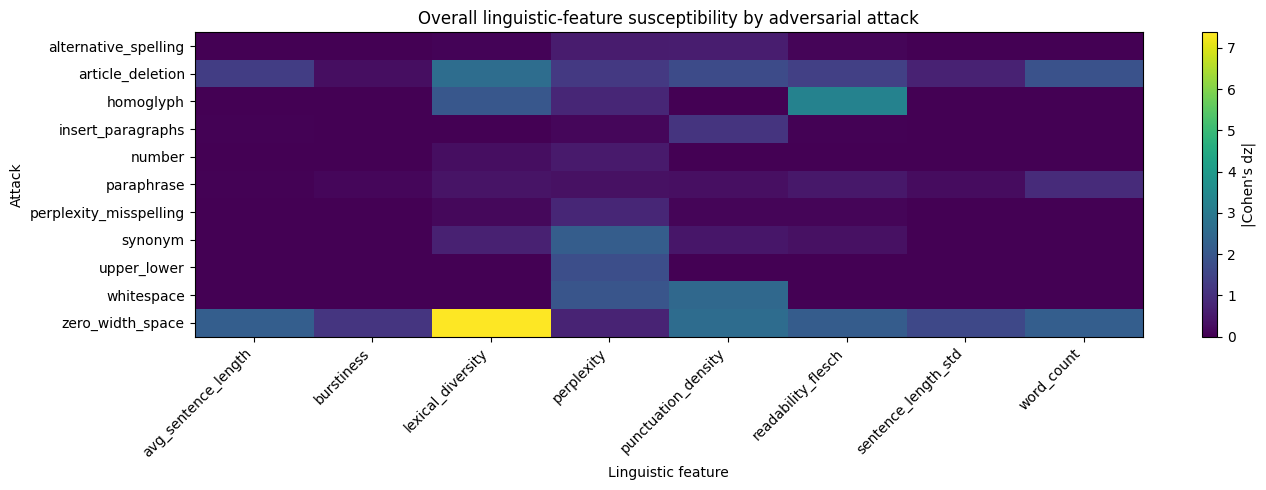

In [ ]:

heat = overall_results.pivot_table(
    index="Attack",
    columns="Linguistic_Feature",
    values="Abs_Paired_Effect_dz",
    aggfunc="first",
)

fig, ax = plt.subplots(figsize=(14, max(5, 0.45 * len(heat))))
im = ax.imshow(heat.values, aspect="auto")

ax.set_xticks(np.arange(heat.shape[1]))
ax.set_xticklabels(heat.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(heat.shape[0]))
ax.set_yticklabels(heat.index)

ax.set_title("Overall linguistic-feature susceptibility by adversarial attack")
ax.set_xlabel("Linguistic feature")
ax.set_ylabel("Attack")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("|Cohen's dz|")

plt.tight_layout()
plt.show()


In [ ]:

overall_results.to_csv(
    OUTPUT_DIR / "01_overall_attack_feature_results.csv", index=False
)
domain_results.to_csv(
    OUTPUT_DIR / "02_domain_attack_feature_results.csv", index=False
)
publication_table.to_csv(
    OUTPUT_DIR / "03_publication_table_domain_attack_human.csv", index=False
)
susceptibility.to_csv(
    OUTPUT_DIR / "04_feature_susceptibility_by_attack_domain.csv", index=False
)
feature_stability.to_csv(
    OUTPUT_DIR / "05_overall_feature_stability.csv", index=False
)
attack_domain_summary.to_csv(
    OUTPUT_DIR / "06_attack_domain_summary.csv", index=False
)
overall_attack_summary.to_csv(
    OUTPUT_DIR / "07_overall_attack_summary.csv", index=False
)
domain_drift_matrix.to_csv(
    OUTPUT_DIR / "08_domain_drift_matrix.csv", index=False
)
human_convergence_matrix.to_csv(
    OUTPUT_DIR / "09_human_convergence_matrix.csv", index=False
)
indicator_stability.to_csv(
    OUTPUT_DIR / "10_perplexity_burstiness_stability.csv", index=False
)

excel_path = OUTPUT_DIR / "final_linguistic_attack_analysis.xlsx"

try:
    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        overall_results.to_excel(
            writer, sheet_name="Overall_Attack_Features", index=False
        )
        domain_results.to_excel(
            writer, sheet_name="Domain_Attack_Features", index=False
        )
        publication_table.to_excel(
            writer, sheet_name="Publication_Table", index=False
        )
        susceptibility.to_excel(
            writer, sheet_name="Susceptibility", index=False
        )
        feature_stability.to_excel(
            writer, sheet_name="Feature_Stability", index=False
        )
        attack_domain_summary.to_excel(
            writer, sheet_name="Attack_Domain_Summary", index=False
        )
        overall_attack_summary.to_excel(
            writer, sheet_name="Overall_Attack_Summary", index=False
        )
        domain_drift_matrix.to_excel(
            writer, sheet_name="Domain_Drift_Matrix", index=False
        )
        human_convergence_matrix.to_excel(
            writer, sheet_name="Human_Convergence", index=False
        )
        indicator_stability.to_excel(
            writer, sheet_name="PPL_Burstiness", index=False
        )

    print("Excel workbook saved:", excel_path)

except Exception as e:
    print("Excel export skipped:", e)
    print("If required, run: !pip install -q openpyxl")

print("\nAll CSV analysis files saved in:")
print(OUTPUT_DIR)


Excel workbook saved: /content/drive/MyDrive/Linguistics_feature/final_analysis/final_linguistic_attack_analysis.xlsx

All CSV analysis files saved in:
/content/drive/MyDrive/Linguistics_feature/final_analysis


In [ ]:

print("MOST SUSCEPTIBLE FEATURES")
display(
    feature_stability[
        [
            "Susceptibility_Rank",
            "Linguistic_Feature",
            "Median_Abs_Effect_dz",
            "Percent_AttackDomain_Significant_FDR",
            "Percent_AttackDomain_Toward_Human",
            "Median_Human_Convergence",
        ]
    ].round(4)
)

print("\nATTACKS WITH LARGEST OVERALL DRIFT")
display(
    overall_attack_summary[
        [
            "Attack",
            "Median_Abs_Attack_Effect_dz",
            "FDR_Significant_Features_Wilcoxon",
            "Toward_Human_Percent",
            "Away_From_Human_Percent",
            "Median_Human_Convergence",
            "Most_Susceptible_Feature",
        ]
    ].round(4)
)

print("\nPERPLEXITY AND BURSTINESS")
display(indicator_stability.round(4))


MOST SUSCEPTIBLE FEATURES


,Susceptibility_Rank,Linguistic_Feature,Median_Abs_Effect_dz,Percent_AttackDomain_Significant_FDR,Percent_AttackDomain_Toward_Human,Median_Human_Convergence
0,1,perplexity,1.7514,100.0000,70.4545,0.2164
1,2,punctuation_density,0.5009,70.4545,12.5000,0.0000
2,3,lexical_diversity,0.2379,69.3182,18.1818,0.0000
3,4,readability_flesch,0.1591,63.6364,12.5000,0.0000
4,5,avg_sentence_length,0.0000,31.8182,4.5455,0.0000
5,6,burstiness,0.0000,28.4091,9.0909,0.0000
6,7,sentence_length_std,0.0000,30.6818,7.9545,0.0000
7,8,word_count,0.0000,27.2727,2.2727,0.0000



ATTACKS WITH LARGEST OVERALL DRIFT


,Attack,Median_Abs_Attack_Effect_dz,FDR_Significant_Features_Wilcoxon,Toward_Human_Percent,Away_From_Human_Percent,Median_Human_Convergence,Most_Susceptible_Feature
10,zero_width_space,2.1650,8,0.0,100.0,-2.1258,lexical_diversity
1,article_deletion,1.3636,8,25.0,12.5,-0.0296,lexical_diversity
5,paraphrase,0.3231,8,25.0,37.5,-0.0245,word_count
7,synonym,0.1690,4,12.5,12.5,0.0000,perplexity
6,perplexity_misspelling,0.0497,4,12.5,0.0,0.0000,perplexity
0,alternative_spelling,0.0394,4,0.0,0.0,0.0000,punctuation_density
3,insert_paragraphs,0.0194,4,0.0,12.5,-0.0001,punctuation_density
2,homoglyph,0.0000,3,12.5,25.0,0.0000,readability_flesch
4,number,0.0000,2,0.0,0.0,0.0000,perplexity
8,upper_lower,0.0000,1,12.5,0.0,0.0000,perplexity



PERPLEXITY AND BURSTINESS


,Attack,Domain,Linguistic_Feature,N_OriginalAttack_Pairs,N_Matched_Human_Sources,Original_AI_Mean,Attacked_AI_Mean,Human_Mean,Percent_Change,Paired_Effect_Cohens_dz,Wilcoxon_FDR,Abs_g_Before,Abs_g_After,Human_Convergence,Matched_Human_Gap_Convergence,Movement
4,alternative_spelling,abstracts,burstiness,3532,1766,0.2022,0.2022,0.3569,0.0000,0.0000,1.0000,1.4663,1.4663,0.0000,0.0000,Little/No Change
12,alternative_spelling,books,burstiness,3562,1781,0.2533,0.2533,0.4460,0.0000,0.0000,1.0000,1.7195,1.7195,0.0000,0.0000,Little/No Change
20,alternative_spelling,news,burstiness,3560,1780,0.2437,0.2437,0.3993,0.0000,0.0000,1.0000,1.5685,1.5685,0.0000,0.0000,Little/No Change
28,alternative_spelling,poetry,burstiness,3542,1771,0.1350,0.1350,0.5554,0.0000,0.0000,1.0000,1.7495,1.7495,0.0000,0.0000,Little/No Change
36,alternative_spelling,recipes,burstiness,3544,1772,1.1162,1.1162,0.9409,0.0000,0.0000,1.0000,0.6872,0.6872,0.0000,0.0000,Little/No Change
44,alternative_spelling,reddit,burstiness,3558,1778,0.3709,0.3709,0.4963,0.0000,0.0000,1.0000,0.8321,0.8321,0.0000,0.0000,Little/No Change
52,alternative_spelling,reviews,burstiness,1886,943,0.2807,0.2807,0.5704,0.0000,0.0000,1.0000,1.8858,1.8858,0.0000,0.0000,Little/No Change
60,alternative_spelling,wiki,burstiness,3558,1779,0.2944,0.2944,0.4660,0.0000,0.0000,1.0000,1.3340,1.3340,0.0000,0.0000,Little/No Change
68,article_deletion,abstracts,burstiness,3532,1766,0.2022,0.2030,0.3569,0.3971,0.0470,0.0036,1.4663,1.4581,0.0083,0.0037,Little/No Change
76,article_deletion,books,burstiness,3562,1781,0.2533,0.2532,0.4460,-0.0491,-0.0091,0.5320,1.7195,1.7232,-0.0037,-0.0004,Little/No Change
